# 03 — Preprocesamiento de secuencias
1. decode clips a sec de numpy 
2. estructura de pixeles 
3. evol temporal 
4. grayscale 
5. distribucion long -> transcripciones 
6. normalizacion 
7. denuevo aleat de secuencias 

## 1. Imports y configuración

In [1]:
import json
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_SEED = 18
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

OpenCV: 4.10.0
NumPy: 1.26.4
Pandas: 2.3.3


## 2. Cargar metadata y construir el manifiesto

In [2]:
DATA_DIR = Path(r"D:\ViSpeR\clips")
METADATA_PATH = DATA_DIR / "metadata.json"

with open(METADATA_PATH, "r", encoding="utf-8") as f:
    metadata = json.load(f)

records = []
for path_str, item in metadata.items():
    path = Path(path_str)
    records.append({
        "path": path_str,
        "label": item["label"].strip(),
        "frames_metadata": int(item["length"]),
        "duration_seconds": int(item["length"]) / 25,
        "video_id": path.parent.name,
        "clip_id": path.stem,
        "text_length": len(item["label"].strip()),
        "word_count": len(item["label"].split())
    })

clips_df = pd.DataFrame(records)

print("Clips:", len(clips_df))
print("Videos de origen:", clips_df["video_id"].nunique())
display(clips_df.head())

Clips: 1304
Videos de origen: 23


,path,label,frames_metadata,duration_seconds,video_id,clip_id,text_length,word_count
0,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00000.mp4,La ficción es una herramienta poderosa,108,4.32,0YEeb-WLF2w,00000,38,6
1,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00001.mp4,Una tecnología blanda,82,3.28,0YEeb-WLF2w,00001,21,3
2,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00002.mp4,Las tecnologías blandas funcionan de la misma ...,79,3.16,0YEeb-WLF2w,00002,52,8
3,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00003.mp4,Cuando en las historias de la Biblia se nos cu...,178,7.12,0YEeb-WLF2w,00003,114,22
4,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00004.mp4,que las cosas buenas son recompensadas y las c...,110,4.40,0YEeb-WLF2w,00004,71,12


## 3. Función para decodificar un clip

In [3]:
def load_clip(path):
    """Lee un MP4 y devuelve una secuencia con forma (T, H, W, C), en BGR."""
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise RuntimeError(f"No se pudo abrir el clip: {path}")

    frames = []
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        frames.append(frame)

    cap.release()
    if not frames:
        raise RuntimeError(f"No se pudieron decodificar frames: {path}")

    return np.stack(frames, axis=0)


sample_row = clips_df.iloc[0]
sample_sequence = load_clip(sample_row["path"])

print("Clip:", sample_row["path"])
print("Shape (T, H, W, C):", sample_sequence.shape)
print("dtype:", sample_sequence.dtype)
print("Mínimo:", sample_sequence.min())
print("Máximo:", sample_sequence.max())

Clip: D:\ViSpeR\clips\videos\0YEeb-WLF2w\00000.mp4
Shape (T, H, W, C): (108, 96, 96, 3)
dtype: uint8
Mínimo: 0
Máximo: 255


## 4. Validar secuencia decodificada contra metadata

In [4]:
decoded_length = len(sample_sequence)
expected_length = int(sample_row["frames_metadata"])

print("Frames decodificados:", decoded_length)
print("Frames en metadata:", expected_length)
print("Coinciden:", decoded_length == expected_length)

assert decoded_length == expected_length
assert sample_sequence.shape[1:3] == (96, 96)
assert sample_sequence.ndim == 4 and sample_sequence.shape[-1] == 3

Frames decodificados: 108
Frames en metadata: 108
Coinciden: True


## 5. Inspección temporal de una secuencia

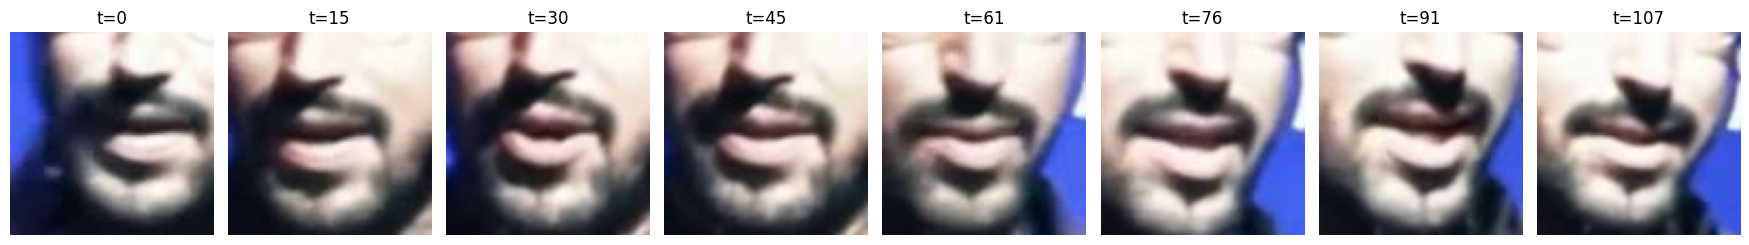

Transcripción: La ficción es una herramienta poderosa


In [5]:
def show_sequence(sequence, n_frames=8):
    total = len(sequence)
    indices = np.linspace(0, total - 1, min(n_frames, total), dtype=int)

    fig, axes = plt.subplots(1, len(indices), figsize=(2.2 * len(indices), 2.6))
    if len(indices) == 1:
        axes = [axes]

    for ax, idx in zip(axes, indices):
        ax.imshow(cv2.cvtColor(sequence[idx], cv2.COLOR_BGR2RGB))
        ax.set_title(f"t={idx}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()


show_sequence(sample_sequence)
print("Transcripción:", sample_row["label"])

## 6. Inspeccionar canales y escala de píxeles

In [6]:
print("Forma:", sample_sequence.shape)
print("Tipo:", sample_sequence.dtype)
print("Rango global:", (int(sample_sequence.min()), int(sample_sequence.max())))

channel_stats = pd.DataFrame({
    "canal": ["B", "G", "R"],
    "media": sample_sequence.mean(axis=(0, 1, 2)),
    "desvio": sample_sequence.std(axis=(0, 1, 2)),
    "min": sample_sequence.min(axis=(0, 1, 2)),
    "max": sample_sequence.max(axis=(0, 1, 2))
})
display(channel_stats)

gray_sequence = np.stack(
    [cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY) for frame in sample_sequence],
    axis=0
)
print("Forma grayscale:", gray_sequence.shape)
print("Rango grayscale:", (int(gray_sequence.min()), int(gray_sequence.max())))

Forma: (108, 96, 96, 3)
Tipo: uint8
Rango global: (0, 255)


,canal,media,desvio,min,max
0,B,137.771825,77.480513,6,255
1,G,130.513727,82.495734,4,255
2,R,137.621335,88.634328,0,255


Forma grayscale: (108, 96, 96)
Rango grayscale: (5, 255)


## 7. Comparar RGB y grayscale

OpenCV decodifica en BGR. Acá comparamos visualmente RGB y grayscale; todavía no elegimos la representación final.

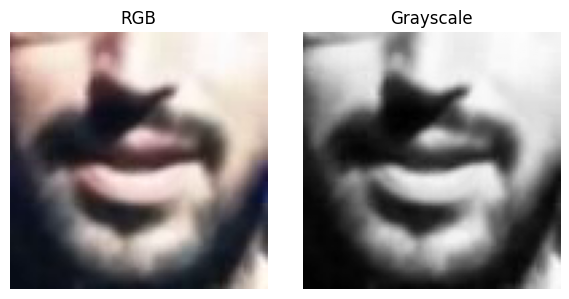

In [7]:
frame_idx = len(sample_sequence) // 2
frame_bgr = sample_sequence[frame_idx]
frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
frame_gray = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2GRAY)

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(frame_rgb)
axes[0].set_title("RGB")
axes[1].imshow(frame_gray, cmap="gray")
axes[1].set_title("Grayscale")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 8. Revisar longitudes de secuencia y texto

,frames_metadata,duration_seconds,text_length,word_count
count,1304.000000,1304.000000,1304.000000,1304.000000
mean,122.309816,4.892393,69.654141,12.680215
std,57.515034,2.300601,32.912440,6.031107
min,40.000000,1.600000,7.000000,2.000000
25%,81.000000,3.240000,46.000000,8.000000
50%,112.000000,4.480000,64.000000,12.000000
75%,152.000000,6.080000,88.000000,16.000000
max,626.000000,25.040000,290.000000,61.000000


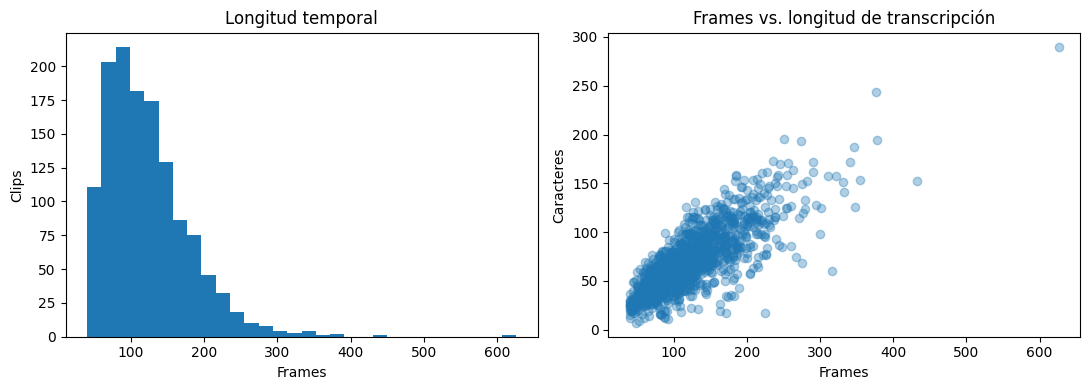

In [8]:
display(clips_df[["frames_metadata", "duration_seconds", "text_length", "word_count"]].describe())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(clips_df["frames_metadata"], bins=30)
axes[0].set_title("Longitud temporal")
axes[0].set_xlabel("Frames")
axes[0].set_ylabel("Clips")

axes[1].scatter(clips_df["frames_metadata"], clips_df["text_length"], alpha=0.35)
axes[1].set_title("Frames vs. longitud de transcripción")
axes[1].set_xlabel("Frames")
axes[1].set_ylabel("Caracteres")
plt.tight_layout()
plt.show()

## 9. Inspección aleatoria de secuencias


Clip: 00028.mp4 | Video: WVVgl0N7tig
Transcripción: porque queríamos generar sinapsis
Shape: (90, 96, 96, 3) | dtype: uint8
Frames metadata: 90 | decodificados: 90


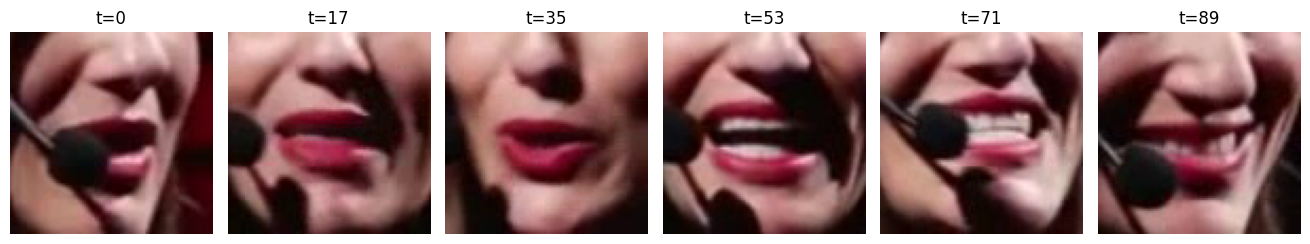


Clip: 00104.mp4 | Video: WVVgl0N7tig
Transcripción: que tenemos Yo los invito y es lo que de alguna forma yo quería compartir con ustedes a emprender
Shape: (156, 96, 96, 3) | dtype: uint8
Frames metadata: 156 | decodificados: 156


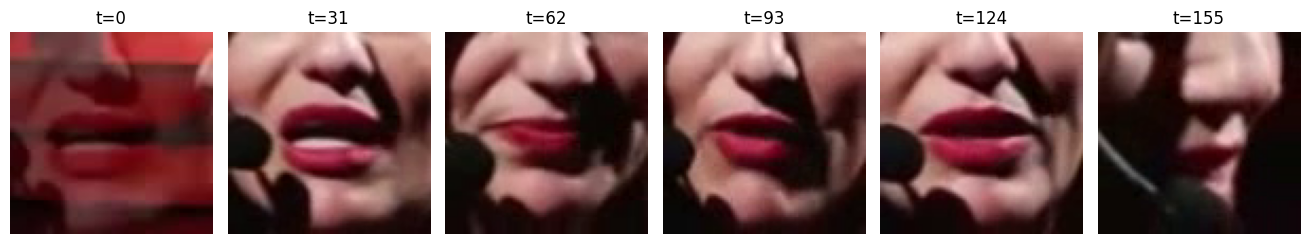


Clip: 00001.mp4 | Video: unuP4RNN3QE
Transcripción: de las más importantes cultivos con mayor y mayor productividad a lo largo del ciclo
Shape: (133, 96, 96, 3) | dtype: uint8
Frames metadata: 133 | decodificados: 133


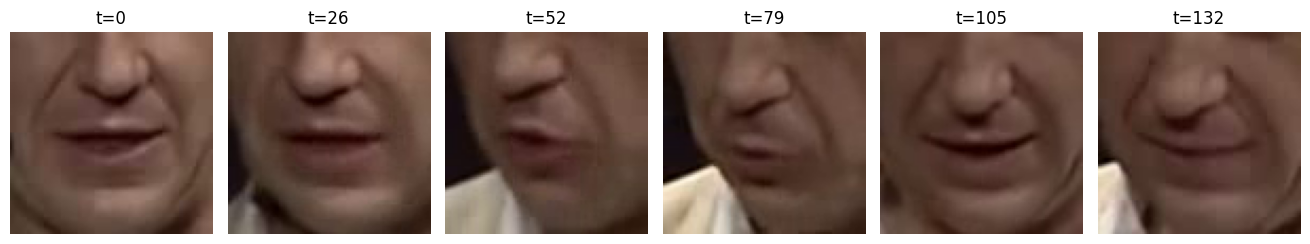


Clip: 00069.mp4 | Video: 0YEeb-WLF2w
Transcripción: Tenemos que estar atentos
Shape: (41, 96, 96, 3) | dtype: uint8
Frames metadata: 41 | decodificados: 41


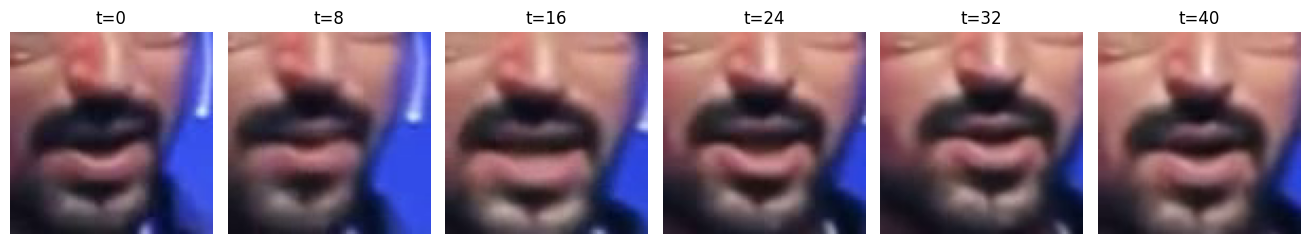


Clip: 00016.mp4 | Video: 0YEeb-WLF2w
Transcripción: Entonces nos imaginamos en Copacabana  paseando por las calles de Río
Shape: (90, 96, 96, 3) | dtype: uint8
Frames metadata: 90 | decodificados: 90


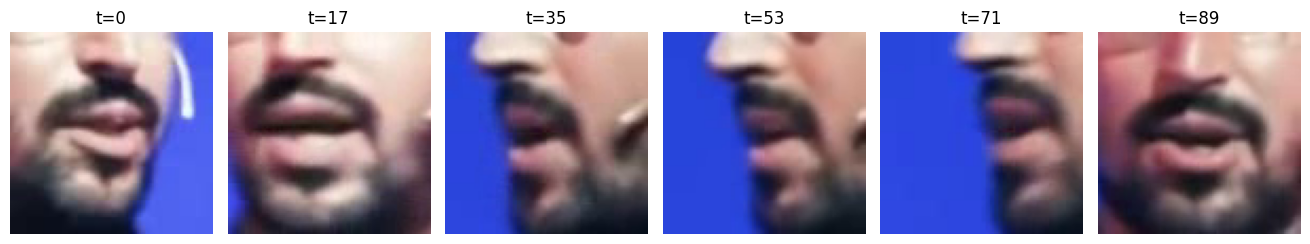

In [9]:
def inspect_random_sequences(n=5, frames_per_clip=6):
    selected = clips_df.sample(n=min(n, len(clips_df)))

    for _, row in selected.iterrows():
        sequence = load_clip(row["path"])
        print(f"\nClip: {Path(row['path']).name} | Video: {row['video_id']}")
        print("Transcripción:", row["label"])
        print("Shape:", sequence.shape, "| dtype:", sequence.dtype)
        print("Frames metadata:", row["frames_metadata"], "| decodificados:", len(sequence))
        assert len(sequence) == int(row["frames_metadata"])
        show_sequence(sequence, n_frames=frames_per_clip)


inspect_random_sequences()

## 10. Probar escalado a [0, 1]

In [10]:
sample_float = sample_sequence.astype(np.float32) / 255.0

print("Original:", sample_sequence.dtype,
      float(sample_sequence.min()), float(sample_sequence.max()))
print("Escalada:", sample_float.dtype,
      float(sample_float.min()), float(sample_float.max()))

Original: uint8 0.0 255.0
Escalada: float32 0.0 1.0


## 11. Conclusiones y decisiones pendientes

Registrar después de ejecutar:

- ¿Todas las secuencias se decodifican completas?
- ¿La forma observada es `(T, 96, 96, 3)`?
- ¿Los valores originales están en `[0, 255]`?
- ¿Qué representación usaremos: RGB o grayscale? Justificar con literatura y con el diseño de inferencia en vivo.
- ¿Escalaremos a `[0, 1]`?
- ¿Conservamos longitudes variables y hacemos padding por batch? **La decisión actual es sí; no truncar secuencias por conveniencia.**

**No guardar todavía un dataset procesado completo.** Primero cerramos estas decisiones y después implementamos la carga eficiente en `04_dataset_pytorch.ipynb`.